<a href="https://colab.research.google.com/github/abhat-phys/phys142-doublewell-groupA/blob/main/double_well_extension.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
from numba import njit
import scipy.sparse as sp
from scipy.sparse.linalg import eigsh
from scipy.linalg import cholesky, solve_triangular

plt.rcParams.update({
  "font.family": "serif",
  "mathtext.fontset": "cm",
  "font.size": 9,
  "axes.labelsize": 9,
  "legend.fontsize": 7,
  "xtick.labelsize": 8,
  "ytick.labelsize": 8,
  "figure.constrained_layout.use": True,
})

SEED = 10142
_run = [0]
def next_seed():
  s = SEED + _run[0]; _run[0] += 1
  return s

@njit
def seed_numba(s):
  np.random.seed(s)

DTAU = 0.1
HIT = 0.6
ALPHAS = [0.35, 0.40, 0.45, 0.50]
BETAS = [1, 2, 4, 8, 12, 16]
N_REP = 3
SWEEPS = 20000

In [2]:
@njit
def V(x, alpha):
  return alpha * x**4 - 2 * x**2 + 1 / alpha

@njit
def dV(x, alpha):
  return 4 * alpha * x**3 - 4 * x

def get_states(alpha, L=6.0, nd=1200, k=2):
  x = np.linspace(-L, L, nd + 1)
  dx = 2 * L / nd
  off = np.full(x.size - 1, -0.5 / dx**2)
  H = sp.diags([off, 1 / dx**2 + V(x, alpha), off], [-1, 0, 1], format="csc")
  E = eigsh(H, k=k, sigma=0, which="LM")[0]
  return np.sort(E)

def H_thermal(E, beta):
  w = np.exp(-beta * (E - E[0]))
  return np.sum(E * w) / np.sum(w)

bench = {}
for a in ALPHAS:
  E = get_states(a, k=40)
  bench[a] = E
  print(f"alpha={a:.2f}  E0={E[0]:.6f}  E1={E[1]:.6f}  dE={E[1]-E[0]:.6f}  E39={E[-1]:.1f}")

alpha=0.35  E0=1.276132  E1=1.340790  dE=0.064657  E39=115.0
alpha=0.40  E0=1.234490  E1=1.346920  dE=0.112430  E39=121.4
alpha=0.45  E0=1.189693  E1=1.358992  dE=0.169299  E39=127.3
alpha=0.50  E0=1.144811  E1=1.376017  dE=0.231205  E39=132.7


In [3]:
@njit
def action(x, dtau, alpha):
  N = x.size
  S = 0.0
  for i in range(N):
    d = x[(i + 1) % N] - x[i]
    S += 0.5 * d * d / dtau + dtau * V(x[i], alpha)
  return S

@njit
def sweep(x, h, dtau, alpha):
  N = x.size
  acc = 0
  for i in range(N):
    xl = x[(i - 1) % N]
    xr = x[(i + 1) % N]
    xo = x[i]
    xn = xo + h * (2 * np.random.random() - 1)
    dS = ((xr - xn)**2 + (xn - xl)**2 - (xr - xo)**2 - (xo - xl)**2) / (2 * dtau)
    dS += dtau * (V(xn, alpha) - V(xo, alpha))
    if dS <= 0 or np.random.random() < np.exp(-dS):
      x[i] = xn
      acc += 1
  return acc

In [4]:
def precision_matrix(N, dtau, w2=8.0):
  A = np.zeros((N, N))
  for i in range(N):
    A[i, i] = 2 / dtau + dtau * w2
    A[i, (i + 1) % N] -= 1 / dtau
    A[i, (i - 1) % N] -= 1 / dtau
  return A

def make_proposal(N, dtau, alpha):
  A = precision_matrix(N, dtau)
  U = cholesky(A)
  mu = 1 / np.sqrt(alpha)
  return A, U, mu

def log_q(x, A, mu, mixture=True):
  yp = x - mu
  lp = -0.5 * yp @ A @ yp
  if not mixture:
    return lp
  ym = x + mu
  return np.logaddexp(lp, -0.5 * ym @ A @ ym)

def draw(U, mu, rng, mixture=True):
  s = 1.0
  if mixture and rng.random() < 0.5:
    s = -1.0
  z = rng.standard_normal(U.shape[0])
  return s * mu + solve_triangular(U, z)

In [5]:
def run_hybrid(alpha, beta, n_sweeps, burn=1000, mixture=True, harmonic_test=False):
  s = next_seed()
  seed_numba(s)
  rng = np.random.default_rng(s)
  N = int(round(beta / DTAU))
  A, U, mu = make_proposal(N, DTAU, alpha)
  if harmonic_test:
    S_of = lambda y: 0.5 * (y - mu) @ A @ (y - mu)
  else:
    S_of = lambda y: action(y, DTAU, alpha)
  x = np.full(N, mu)
  for _ in range(burn):
    sweep(x, HIT, DTAU, alpha)
  acc = np.zeros(n_sweeps)
  cross = np.zeros(n_sweeps, dtype=bool)
  energy = np.zeros(n_sweeps)
  acc_loc = 0
  S_x, lq_x = S_of(x), log_q(x, A, mu, mixture)
  for k in range(n_sweeps):
    if not harmonic_test:
      acc_loc += sweep(x, HIT, DTAU, alpha)
      S_x, lq_x = S_of(x), log_q(x, A, mu, mixture)
    cross[k] = (x.max() > mu / 2) and (x.min() < -mu / 2)
    xp = draw(U, mu, rng, mixture)
    S_p, lq_p = S_of(xp), log_q(xp, A, mu, mixture)
    if np.log(rng.random()) < (-S_p + S_x) + (lq_x - lq_p):
      x[:] = xp
      S_x, lq_x = S_p, lq_p
      acc[k] = 1
    energy[k] = np.mean(V(x, alpha) + 0.5 * x * dV(x, alpha))
  return dict(acc=acc, cross=cross, energy=energy, acc_loc=acc_loc / (n_sweeps * N), seed=s)

In [6]:
def autocorr(f):
  f = np.array(f)
  N = len(f)
  d = f - f.mean()
  c = np.correlate(d, d, mode="full")[N-1:] / N
  return c / c[0]

def tau_int(f):
  rho = autocorr(f)
  tau = 1.0
  for M in range(1, len(rho)):
    tau = 1 + 2 * rho[1: M+1].sum()
    if M >= 5 * tau:
      return tau, M
  return tau, len(rho) - 1

def mean_err(f):
  f = np.asarray(f, dtype=float)
  if f.std() == 0:
    return f.mean(), 0.0, 1.0
  tau, _ = tau_int(f)
  return f.mean(), np.sqrt(tau * f.var() / len(f)), tau

def combine(vals_errs):
  v = np.array([ve[0] for ve in vals_errs])
  e = np.array([ve[1] for ve in vals_errs])
  return v.mean(), np.sqrt(np.sum(e**2)) / len(v)

In [7]:
r = run_hybrid(0.40, 4.0, 2000, burn=0, mixture=False, harmonic_test=True)
print("harmonic test acceptance:", r["acc"].mean())

harmonic test acceptance: 1.0


In [8]:
def lattice_exact(alpha, beta, dtau, obs, L=5.0, ng=801):
  g = np.linspace(-L, L, ng)
  dx = g[1] - g[0]
  Vg = V(g, alpha)
  T = np.exp(-(g[:, None] - g[None, :])**2 / (2 * dtau) - dtau * (Vg[:, None] + Vg[None, :]) / 2) * dx
  w, Q = np.linalg.eigh(T)
  P = (Q * w**int(round(beta / dtau))) @ Q.T
  return np.sum(np.diag(P) * obs(g)) / np.trace(P)

virial = lambda g: V(g, 0.40) + 0.5 * g * dV(g, 0.40)
for beta in [1.0, 2.0]:
  res = [mean_err(run_hybrid(0.40, beta, 40000)["energy"]) for _ in range(N_REP)]
  E_mc, E_err = combine(res)
  E_lat = lattice_exact(0.40, beta, DTAU, virial)
  E_ex = H_thermal(bench[0.40], beta)
  print(f"beta={beta}: MC = {E_mc:.4f} +- {E_err:.4f}  lattice exact = {E_lat:.4f}  "
        f"pull = {(E_mc-E_lat)/E_err:+.2f}  continuum = {E_ex:.4f}  dtau offset = {E_lat-E_ex:+.4f}")

beta=1.0: MC = 1.5184 +- 0.0089  lattice exact = 1.5235  pull = -0.57  continuum = 1.5350  dtau offset = -0.0115
beta=2.0: MC = 1.2948 +- 0.0073  lattice exact = 1.3060  pull = -1.54  continuum = 1.3173  dtau offset = -0.0113


In [9]:
rows = []
t0 = time.time()
for a in ALPHAS:
  dE = bench[a][1] - bench[a][0]
  for beta in BETAS:
    reps = [run_hybrid(a, beta, SWEEPS) for _ in range(N_REP)]
    acc, acc_err = combine([mean_err(r["acc"]) for r in reps])
    acc_nc, acc_nc_err = combine([mean_err(r["acc"][~r["cross"]]) for r in reps])
    f_cr, f_cr_err = combine([mean_err(r["cross"]) for r in reps])
    n_cross = sum(int(r["cross"].sum()) for r in reps)
    n_acc_cross = sum(int(r["acc"][r["cross"]].sum()) for r in reps)
    rows.append(dict(alpha=a, beta=beta, bdE=beta * dE, acc=acc, acc_err=acc_err,
                     acc_nc=acc_nc, acc_nc_err=acc_nc_err, f_cross=f_cr, f_cross_err=f_cr_err,
                     n_cross=n_cross, n_acc_cross=n_acc_cross,
                     acc_loc=np.mean([r["acc_loc"] for r in reps]),
                     seeds=[r["seed"] for r in reps]))
    print(f"a={a:.2f} beta={beta:2d} bdE={beta*dE:5.2f} acc={acc:.4f}+-{acc_err:.4f} "
          f"acc|nocross={acc_nc:.4f}+-{acc_nc_err:.4f} f_cross={f_cr:.3f}+-{f_cr_err:.3f} "
          f"accepted from crossing={n_acc_cross}/{n_cross}  ({time.time()-t0:.0f}s)", flush=True)

a=0.35 beta= 1 bdE= 0.06 acc=0.6805+-0.0090 acc|nocross=0.6806+-0.0090 f_cross=0.000+-0.000 accepted from crossing=0/10  (10s)
a=0.35 beta= 2 bdE= 0.13 acc=0.6203+-0.0084 acc|nocross=0.6223+-0.0077 f_cross=0.003+-0.003 accepted from crossing=0/206  (18s)
a=0.35 beta= 4 bdE= 0.26 acc=0.4618+-0.0075 acc|nocross=0.4686+-0.0065 f_cross=0.015+-0.011 accepted from crossing=0/882  (27s)
a=0.35 beta= 8 bdE= 0.52 acc=0.2871+-0.0064 acc|nocross=0.2907+-0.0062 f_cross=0.014+-0.007 accepted from crossing=0/814  (38s)
a=0.35 beta=12 bdE= 0.78 acc=0.1755+-0.0059 acc|nocross=0.1796+-0.0058 f_cross=0.023+-0.008 accepted from crossing=0/1383  (50s)
a=0.35 beta=16 bdE= 1.03 acc=0.1265+-0.0049 acc|nocross=0.1289+-0.0049 f_cross=0.019+-0.006 accepted from crossing=0/1144  (64s)
a=0.40 beta= 1 bdE= 0.11 acc=0.6744+-0.0082 acc|nocross=0.6746+-0.0082 f_cross=0.000+-0.000 accepted from crossing=0/11  (72s)
a=0.40 beta= 2 bdE= 0.22 acc=0.5852+-0.0075 acc|nocross=0.5888+-0.0070 f_cross=0.006+-0.003 accepted fro

In [10]:
kappa = {}
for a in ALPHAS:
  sel = [rw for rw in rows if rw["alpha"] == a and rw["beta"] >= 4 and rw["acc_nc"] > 0]
  b = np.array([rw["beta"] for rw in sel])
  y = -np.log([rw["acc_nc"] for rw in sel])
  sig = np.array([rw["acc_nc_err"] / rw["acc_nc"] for rw in sel])
  coef, cov = np.polyfit(b, y, 1, w=1 / sig, cov="unscaled")
  chi2 = np.sum(((y - np.polyval(coef, b)) / sig)**2) / (len(b) - 2)
  err = np.sqrt(cov[0, 0] * max(1.0, chi2))
  kappa[a] = (coef[0], err)
  print(f"alpha={a:.2f}: kappa = {coef[0]:.4f} +- {err:.4f}   chi2/dof = {chi2:.2f}")

k_val = np.array([kappa[a][0] for a in ALPHAS])
k_err = np.array([kappa[a][1] for a in ALPHAS])
la, lk, lk_err = np.log(ALPHAS), np.log(k_val), k_err / k_val
(p_slope, p_icpt), p_cov = np.polyfit(la, lk, 1, w=1 / lk_err, cov="unscaled")
p_chi2 = np.sum(((lk - np.polyval([p_slope, p_icpt], la)) / lk_err)**2) / (len(la) - 2)
p_err = np.sqrt(p_cov[0, 0] * max(1.0, p_chi2))
print(f"kappa ~ alpha^({p_slope:.2f} +- {p_err:.2f})   chi2/dof = {p_chi2:.2f}")

alpha=0.35: kappa = 0.1125 +- 0.0051   chi2/dof = 3.35
alpha=0.40: kappa = 0.1418 +- 0.0042   chi2/dof = 0.58
alpha=0.45: kappa = 0.1373 +- 0.0083   chi2/dof = 3.11
alpha=0.50: kappa = 0.1637 +- 0.0105   chi2/dof = 3.30
kappa ~ alpha^(0.93 +- 0.37)   chi2/dof = 3.37


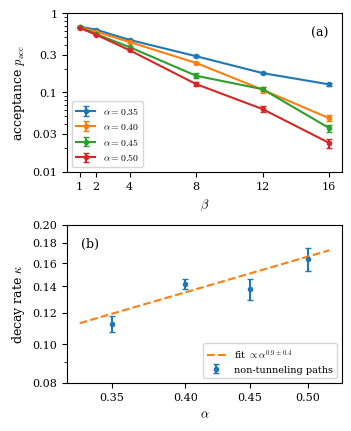

In [11]:
fig, ax = plt.subplots(2, 1, figsize=(3.4, 4.2))

for a in ALPHAS:
  sel = [rw for rw in rows if rw["alpha"] == a]
  ax[0].errorbar([rw["beta"] for rw in sel], [rw["acc"] for rw in sel],
                 yerr=[rw["acc_err"] for rw in sel], fmt="o-", ms=3, capsize=2,
                 label=fr"$\alpha = {a:.2f}$")
ax[0].set(yscale="log", xlabel=r"$\beta$", ylabel=r"acceptance $p_{\rm acc}$")
ax[0].set_xticks(BETAS)
ax[0].set_yticks([0.01, 0.03, 0.1, 0.3, 1.0])
ax[0].set_yticklabels(["0.01", "0.03", "0.1", "0.3", "1"])
ax[0].yaxis.set_minor_formatter(NullFormatter())
ax[0].legend(loc="lower left")
ax[0].text(0.95, 0.92, "(a)", transform=ax[0].transAxes, ha="right", va="top")

ax[1].errorbar(ALPHAS, k_val, yerr=k_err, fmt="o", ms=3, capsize=2, label="non-tunneling paths")
aa = np.linspace(0.33, 0.52, 50)
ax[1].plot(aa, np.exp(p_icpt) * aa**p_slope, "--",
           label=fr"fit $\propto \alpha^{{{p_slope:.1f} \pm {p_err:.1f}}}$")
ax[1].set(xscale="log", yscale="log", xlabel=r"$\alpha$", ylabel=r"decay rate $\kappa$")
ax[1].set_xticks(ALPHAS)
ax[1].set_xticklabels([f"{a:.2f}" for a in ALPHAS])
ax[1].set_yticks([0.08, 0.1, 0.12, 0.14, 0.16, 0.18, 0.2])
ax[1].set_yticklabels(["0.08", "0.10", "0.12", "0.14", "0.16", "0.18", "0.20"])
ax[1].xaxis.set_minor_formatter(NullFormatter())
ax[1].yaxis.set_minor_formatter(NullFormatter())
ax[1].legend(loc="lower right")
ax[1].text(0.05, 0.92, "(b)", transform=ax[1].transAxes, ha="left", va="top")

plt.savefig("fig_extension.pdf")
plt.show()

In [12]:
summary = []
for a in ALPHAS:
  sel = [rw for rw in rows if rw["alpha"] == a]
  last = sel[-1]
  summary.append({"α": f"{a:.2f}",
                  "ΔE": f"{bench[a][1]-bench[a][0]:.4f}",
                  "κ": f"{kappa[a][0]:.3f} ± {kappa[a][1]:.3f}",
                  f"f_cross (β={last['beta']})": f"{last['f_cross']:.2f} ± {last['f_cross_err']:.2f}",
                  "accepted from tunneling paths": f"{sum(rw['n_acc_cross'] for rw in sel)} / {sum(rw['n_cross'] for rw in sel)}"})
display(pd.DataFrame(summary).style.hide(axis="index"))

full = pd.DataFrame([{"α": f"{rw['alpha']:.2f}", "β": rw["beta"], "βΔE": f"{rw['bdE']:.2f}",
                      "p_acc": f"{rw['acc']:.4f} ± {rw['acc_err']:.4f}",
                      "p_acc (non-tunneling)": f"{rw['acc_nc']:.4f} ± {rw['acc_nc_err']:.4f}",
                      "f_cross": f"{rw['f_cross']:.3f} ± {rw['f_cross_err']:.3f}",
                      "local acc": f"{rw['acc_loc']:.2f}",
                      "seeds": ", ".join(str(s) for s in rw["seeds"])} for rw in rows])
display(full.style.hide(axis="index"))

α,ΔE,κ,f_cross (β=16),accepted from tunneling paths
0.35,0.0647,0.113 ± 0.005,0.02 ± 0.01,0 / 4439
0.40,0.1124,0.142 ± 0.004,0.41 ± 0.07,0 / 43252
0.45,0.1693,0.137 ± 0.008,0.46 ± 0.08,1 / 58329
0.50,0.2312,0.164 ± 0.011,0.59 ± 0.09,1 / 83646


α,β,βΔE,p_acc,p_acc (non-tunneling),f_cross,local acc,seeds
0.35,1,0.06,0.6805 ± 0.0090,0.6806 ± 0.0090,0.000 ± 0.000,0.53,"10149, 10150, 10151"
0.35,2,0.13,0.6203 ± 0.0084,0.6223 ± 0.0077,0.003 ± 0.003,0.53,"10152, 10153, 10154"
0.35,4,0.26,0.4618 ± 0.0075,0.4686 ± 0.0065,0.015 ± 0.011,0.53,"10155, 10156, 10157"
0.35,8,0.52,0.2871 ± 0.0064,0.2907 ± 0.0062,0.014 ± 0.007,0.53,"10158, 10159, 10160"
0.35,12,0.78,0.1755 ± 0.0059,0.1796 ± 0.0058,0.023 ± 0.008,0.53,"10161, 10162, 10163"
0.35,16,1.03,0.1265 ± 0.0049,0.1289 ± 0.0049,0.019 ± 0.006,0.53,"10164, 10165, 10166"
0.40,1,0.11,0.6744 ± 0.0082,0.6746 ± 0.0082,0.000 ± 0.000,0.53,"10167, 10168, 10169"
0.40,2,0.22,0.5852 ± 0.0075,0.5888 ± 0.0070,0.006 ± 0.003,0.53,"10170, 10171, 10172"
0.40,4,0.45,0.4340 ± 0.0070,0.4399 ± 0.0065,0.014 ± 0.005,0.53,"10173, 10174, 10175"
0.40,8,0.90,0.2361 ± 0.0071,0.2442 ± 0.0067,0.033 ± 0.009,0.53,"10176, 10177, 10178"


In [13]:
def to_json(v):
  if isinstance(v, (list, tuple)):
    return [to_json(u) for u in v]
  if isinstance(v, (int, str)):
    return v
  return float(v)

with open("extension_results.json", "w") as fh:
  json.dump(dict(seed=SEED, dtau=DTAU, hit=HIT, sweeps=SWEEPS, n_rep=N_REP,
                 dE={str(a): float(bench[a][1] - bench[a][0]) for a in ALPHAS},
                 rows=[{k: to_json(v) for k, v in rw.items()} for rw in rows],
                 kappa={str(a): [float(kappa[a][0]), float(kappa[a][1])] for a in ALPHAS},
                 kappa_power=[float(p_slope), float(p_err)]), fh, indent=1)
print("saved")

saved
